# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox. The TTPLA dataset contains Transmission Towers and Power Lines annotated with point coordinates delineating the objects polygons.

## Import the required packages

In [ ]:
from aitlas.datasets import TTPLADataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/ttpla/data_original_size_v1/data_original_size",
}
dataset = TTPLADataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1242


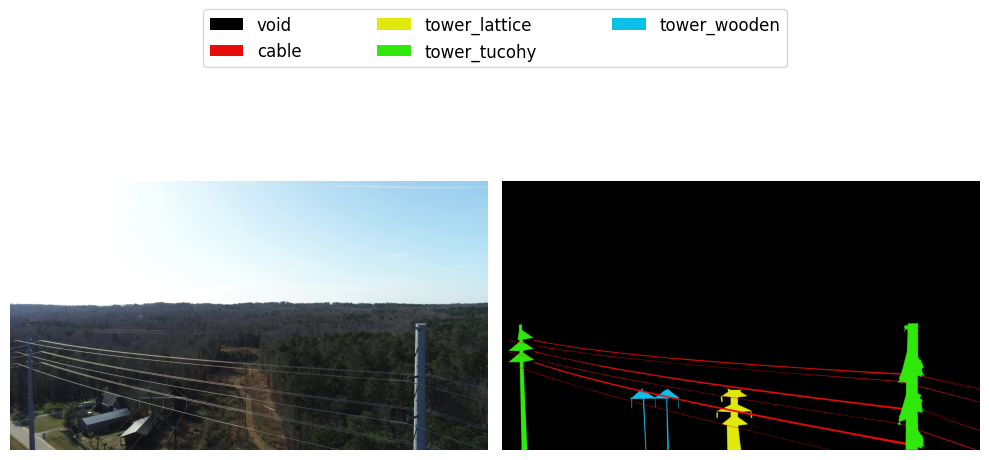

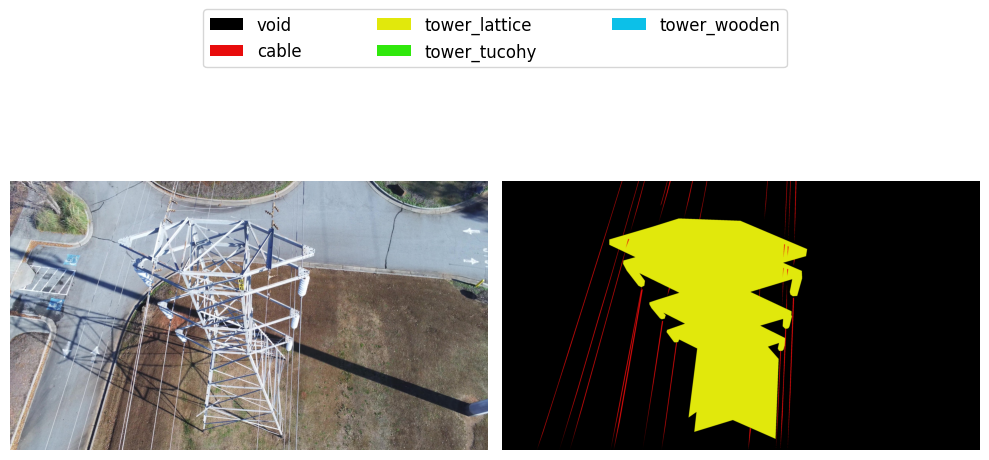

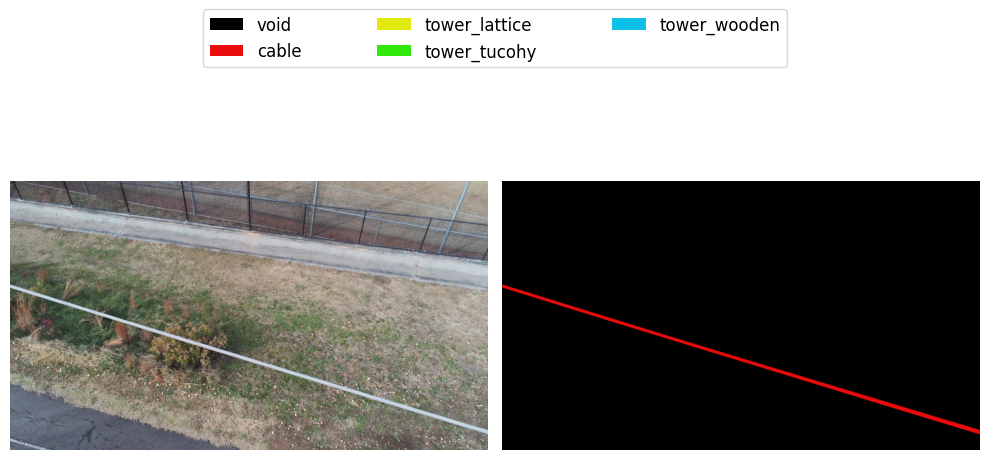

In [12]:
dataset.show_image(15);
dataset.show_image(200);
dataset.show_image(100);

In [6]:
dataset.data_distribution_table()

,Number of pixels
void,10301382549
cable,1138361837
tower_lattice,247220169
tower_tucohy,113429237
tower_wooden,111233621


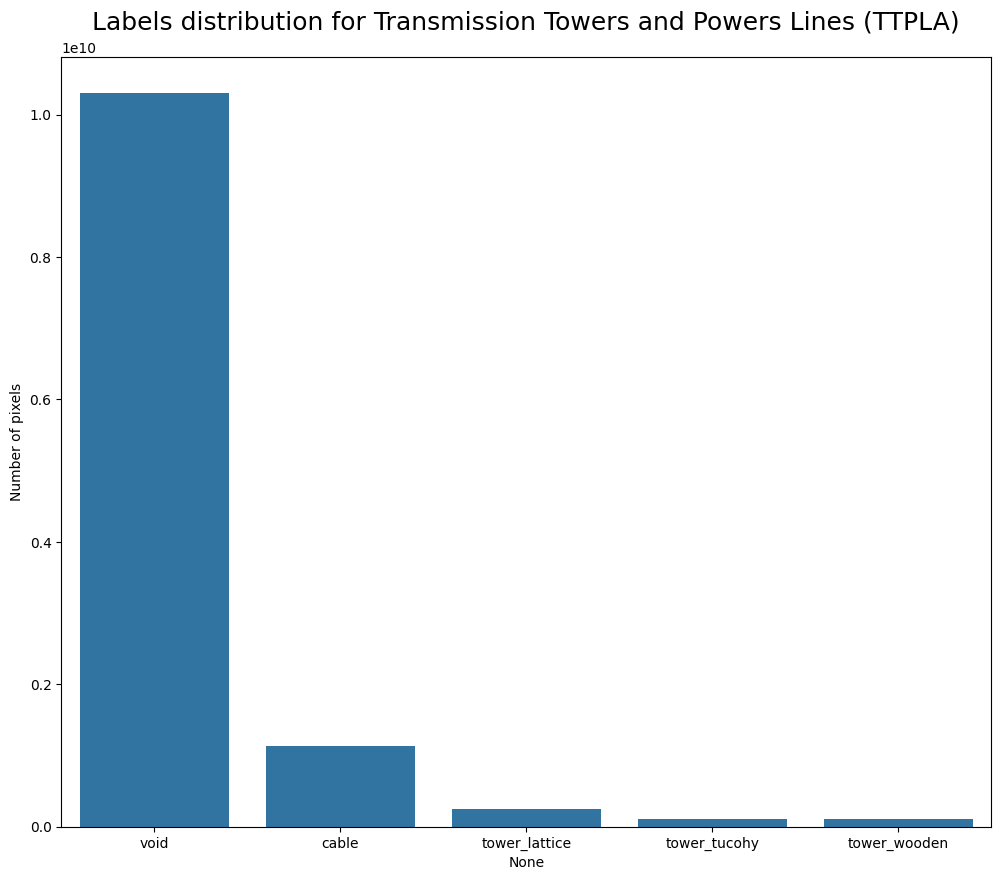

In [7]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/ttpla/data_original_size_v1/data_original_size",
    "csv_file": "./data/ttpla/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = TTPLADataset(train_dataset_config)

len(train_dataset)

994

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/TTLPA"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [8]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-25 07:14:32,452 INFO Starting training.
training: 100%|██████████| 125/125 [05:48<00:00,  2.79s/it]
2025-09-25 07:20:20,793 INFO epoch: 1, time: 348, loss:  0.55758
testing on train set: 100%|██████████| 125/125 [05:19<00:00,  2.56s/it]
2025-09-25 07:25:42,223 INFO IOU:0.636447705147344, IOU mean:0.21482001536069167, IOU per Class:[0.8790093  0.00170428 0.18844319 0.0049433  0.        ]
training: 100%|██████████| 125/125 [05:22<00:00,  2.58s/it]
2025-09-25 07:31:04,425 INFO epoch: 2, time: 322, loss:  0.36766
testing on train set: 100%|██████████| 125/125 [05:37<00:00,  2.70s/it]
2025-09-25 07:36:42,347 INFO IOU:0.9042396132879453, IOU mean:0.3015167247831985, IOU per Class:[0.92572317 0.         0.58186045 0.         0.        ]
training: 100%|██████████| 125/125 [05:28<00:00,  2.63s/it]
2025-09-25 07:42:11,101 INFO epoch: 3, time: 329, loss:  0.20350
testing on train set: 100%|██████████| 125/125 [05:18<00:00,  2.55s/it]
2025-09-25 07:47:29,844 INFO IOU:0.9053446695956832, IO

0.05021519272380192

## Evaluate the model ##

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "num_workers": 4,
    "data_dir" : "./data/ttpla/data_original_size_v1/data_original_size",
    "csv_file": "./data/ttpla/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}

test_dataset = TTPLADataset(test_dataset_config)
len(test_dataset)

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/TTLPA/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-09-25 09:06:06,782 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/TTLPA/checkpoint.pth.tar
2025-09-25 09:06:07,268 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/TTLPA/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 16/16 [00:39<00:00,  2.49s/it]


[{'IOU': 0.9151963481614757,
  'IOU mean': 0.32390783626263653,
  'IOU per Class': array([0.93254649, 0.        , 0.68699269, 0.        , 0.        ])}]

## Predictions ##

2025-09-25 09:08:21,201 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/TTLPA/checkpoint.pth.tar
2025-09-25 09:08:21,524 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/TTLPA/checkpoint.pth.tar at epoch 11


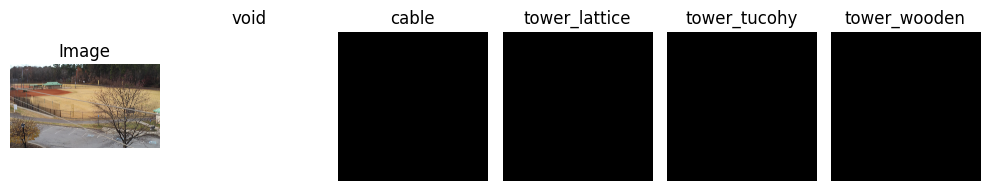

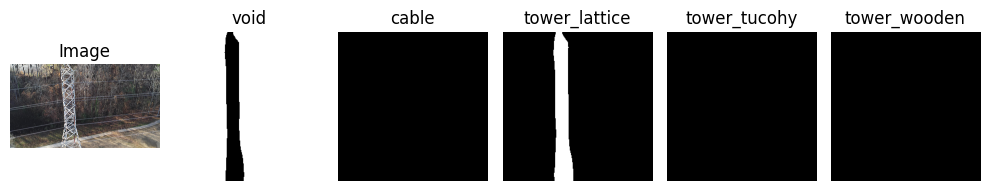

In [ ]:
model_path = "./data/experiments/TTLPA/checkpoint.pth.tar"
labels = [
        "void",
        "cable",
        "tower_lattice",
        "tower_tucohy",
        "tower_wooden"
    ]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/ttpla/data_original_size_v1/data_original_size/39_00211.jpg')
fig = model.predict_masks(image, labels, transform)
image = image_loader('./data/ttpla/data_original_size_v1/data_original_size/74_00495.jpg')
fig = model.predict_masks(image, labels, transform)